## CT4101 - Milestone 3: Model comparison
This milestone compares KNN and Random Forest against the majority-class baseline from Milestone 2. Below contains code directly copied from Milestone 2. Milestone 3 starts below!

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# load the dataset
df = pd.read_csv(
    "../data/risk_factors_cervical_cancer.csv",
    na_values=["?"]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (858, 36)


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,...,NaN,NaN,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0


## 2 - data audit 
# 2.1 data types and any missing values
I am going to examine the dataset for missing values and variables before determining which is the best pre-processing method for this 

In [24]:
# check data types
print("Data types:")
print(df.dtypes.value_counts())

# count missing values per column
missing_values = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

# display columns containing missing values
display(
    missing_values[missing_values["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

Data types:
float64    26
int64      10
Name: count, dtype: int64


,Missing Count,Missing Percentage
STDs: Time since first diagnosis,787,91.72
STDs: Time since last diagnosis,787,91.72
IUD (years),117,13.64
IUD,117,13.64
Hormonal Contraceptives,108,12.59
Hormonal Contraceptives (years),108,12.59
STDs (number),105,12.24
STDs,105,12.24
STDs:vulvo-perineal condylomatosis,105,12.24
STDs:vaginal condylomatosis,105,12.24


# 2.2 duplicates and target distribution
I'm going to check for duplicate rows and see how many patients have positive or negative biopsy results


In [25]:
# check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# check number of positive/negative biopsy results
print("\nBiopsy result counts:")
print(df["Biopsy"].value_counts())

# percentage of each biopsy result
print("\nBiopsy result percentages:")
print((df["Biopsy"].value_counts(normalize=True) * 100).round(2))

# double-check for missing values in the target variable
print("\nMissing values in Biopsy column:")
print("Columns with missing values:", df.isna().any().sum())



Duplicate rows: 23

Biopsy result counts:
Biopsy
0    803
1     55
Name: count, dtype: int64

Biopsy result percentages:
Biopsy
0    93.59
1     6.41
Name: proportion, dtype: float64

Missing values in Biopsy column:
Columns with missing values: 26


Output: 
There are 23 duplicate rows in the dataset. This is something I need to consider before splitting the data as this could effect the evaluation results. As stated before the biopsy results are quite imbalanced as there are 803 negative biopsy results and there are 55 positive biopsy results. This is important to note as a model could achieve high accuracy by predicting negative for each patient without identifing any positive cases. Which is why I need to put emphasis on recall when doing this assignment. There are also 26 columns with missing values which I will also need to handle during pre processing.

# 2.3 check for outliers
I'm gonna take a look at the summary statistics to see if there are any unusual values which may need to be looked into

In [26]:
display(df.describe().T)

# examine numerical features closer
columns_to_examine = [
    "Age", "Number of sexual partners", "First sexual intercourse", "Num of pregnancies", "Smokes (years)"]

display(df[columns_to_examine].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,858.0,26.820513,8.497948,13.0,20.0,25.0,32.0,84.0
Number of sexual partners,832.0,2.527644,1.667760,1.0,2.0,2.0,3.0,28.0
First sexual intercourse,851.0,16.995300,2.803355,10.0,15.0,17.0,18.0,32.0
Num of pregnancies,802.0,2.275561,1.447414,0.0,1.0,2.0,3.0,11.0
Smokes,845.0,0.145562,0.352876,0.0,0.0,0.0,0.0,1.0
Smokes (years),845.0,1.219721,4.089017,0.0,0.0,0.0,0.0,37.0
Smokes (packs/year),845.0,0.453144,2.226610,0.0,0.0,0.0,0.0,37.0
Hormonal Contraceptives,750.0,0.641333,0.479929,0.0,0.0,1.0,1.0,1.0
Hormonal Contraceptives (years),750.0,2.256419,3.764254,0.0,0.0,0.5,3.0,30.0
IUD,741.0,0.112011,0.315593,0.0,0.0,0.0,0.0,1.0


,count,mean,std,min,25%,50%,75%,max
Age,858.0,26.820513,8.497948,13.0,20.0,25.0,32.0,84.0
Number of sexual partners,832.0,2.527644,1.667760,1.0,2.0,2.0,3.0,28.0
First sexual intercourse,851.0,16.995300,2.803355,10.0,15.0,17.0,18.0,32.0
Num of pregnancies,802.0,2.275561,1.447414,0.0,1.0,2.0,3.0,11.0
Smokes (years),845.0,1.219721,4.089017,0.0,0.0,0.0,0.0,37.0


output findings:
There are a few high values in the dataset. For example the maximum number of sexual partners is 28 compared to the medium of 2, and the maximum number of pregnencies is 11 compared to a median of 2. I'm not going to remove them now however I will consider their impact during preprocessing and modellng 

In [27]:
# noting which columns have more then half of values missing
missing_values = df.isna().mean() * 100

print("\nColumns with more than 50% missing values:")
print(missing_values[missing_values > 50])

# check columns with one one unique non missing value
print("\nColumns with only one unique non-missing value:")
print(df.columns[df.nunique(dropna=True) == 1].tolist())


Columns with more than 50% missing values:
STDs: Time since first diagnosis    91.724942
STDs: Time since last diagnosis     91.724942
dtype: float64

Columns with only one unique non-missing value:
['STDs:cervical condylomatosis', 'STDs:AIDS']


Final thoughts of my data audit:
The dataset contains 858 records and 36 columns. There are 23 duplicate rows however these may represent different pateints with the same information which I haven't removed yet. The target value is imbalanced which will be important when evaluating the baseline model. There are 26 columns with missing values. Two columns are both related to the timing of the stf diagnosis so I will probably exclude them. I also found two std related columns with only one unique recorded value which I will exclude as they dont provide any useful information. 

# 3. data preprocessing
I'm going to remove columns now with too much data missing, columns with no variation and test results which dont align with my prediction question

In [28]:
# columns to exclude
columns_to_exclude = [
    "STDs: Time since first diagnosis",
    "STDs: Time since last diagnosis",
    "STDs:cervical condylomatosis",
    "STDs:AIDS",
    "Hinselmann",
    "Schiller",
    "Citology"
]

# divide input features and target variable
X = df.drop(columns=columns_to_exclude + ["Biopsy"])
Y = df["Biopsy"]

print("\nInput features shape:", X.shape)
print("Target variable shape:", Y.shape)
print("Missing values in target variable:", Y.isna().sum())


Input features shape: (858, 28)
Target variable shape: (858,)
Missing values in target variable: 0


In [29]:
# train/test split is based on the approach outlined in week 4 of the lectures
# stratification is used as the biopsy results are imbalanced

from sklearn.model_selection import train_test_split

# split data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\n positive biopsey percentage in training set:")
print(round(Y_train.mean() * 100, 2))

print("\n positive biopsey percentage in testing set:")
print(round(Y_test.mean() * 100, 2))


Training set shape: (686, 28)
Testing set shape: (172, 28)

 positive biopsey percentage in training set:
6.41

 positive biopsey percentage in testing set:
6.4


# 3.1 preprocessing pipeline
I'm going to use median imputation for numerical features and most frequent imputation for binary features. Im also going to standardise the numerical features as some have larger ranges then others. When I'm using KNN later on this will be needed. Preprocessing will be fit only with training data to avoid data leakage


In [30]:
# preprocessing approach based on week 3 lecture
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# identify binary and continuous features
binary_cols = [
    col for col in X_train.columns
    if set(X_train[col].dropna().unique()).issubset({0, 1})
]

numeric_cols = [
    col for col in X_train.columns
    if col not in binary_cols
]

print("\nBinary columns:", len(binary_cols))
print ("\nNumeric columns:", len(numeric_cols))

# preprocessing for numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# preprocessing for binary columns
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

#combine both preprocessing 
preprocessor = ColumnTransformer([
    ("binary", binary_pipeline, binary_cols),
    ("numeric", numeric_pipeline, numeric_cols)
])







Binary columns: 18

Numeric columns: 10


In [31]:
# fit preprocesing on training data only 
X_train_preprocessed = preprocessor.fit_transform(X_train)

# apply same preprocessing to test data
X_test_preprocessed = preprocessor.transform(X_test)

print("Training data shape:", X_train_preprocessed.shape)
print("Testing data shape:", X_test_preprocessed.shape)

# check for any missing values 
print("Missing values in training data:", np.isnan(X_train_preprocessed).sum())
print("Missing values in testing data:", np.isnan(X_test_preprocessed).sum())

Training data shape: (686, 28)
Testing data shape: (172, 28)
Missing values in training data: 0
Missing values in testing data: 0


Both training sets and testing sets still containn 28 features and there are no missing values remaining. The imputer and scaler were fitted using the training data only to avoid data leakage

# 4. Baseline Model 
For my baseline I'm using a majority class classifier. Since most patients in the dataset have a negative biopsy result, this model will predict a negative biopsy result for every patient which will give me something to compare to in Milestone 3. 

In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

# create baseline model using the prepocessing pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, Y_train)

y_pred = baseline_model.predict(X_test)

print("Predicted biopsy results")
print(pd.Series(y_pred).value_counts())

Predicted biopsy results
0    172
Name: count, dtype: int64


# 4.1 baseline evaluation
I will evaluate the baseline using accuracy, precision, recall and F1-score, as outlined in my Milestone 1 proposal.

In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# calculate baseline evaluation metrics
accuracy = accuracy_score(Y_test, y_pred)
precision = precision_score(Y_test, y_pred, zero_division=0)
recall = recall_score(Y_test, y_pred, zero_division=0)
f1 = f1_score(Y_test, y_pred, zero_division=0)

print("Baseline Evaluation Results:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

# confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, y_pred))


Baseline Evaluation Results:
Accuracy: 0.9360
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000

Confusion Matrix:
[[161   0]
 [ 11   0]]


output:
The baseline achieved the accuracy of 93.6% which looks quite good. However the precision, recall and F1-score is all 0. Looking at the confusion matrix, the model correctly predicted 161 negative biopsies but failed to catch any of the positive cases. This is accurate as the majority class classifier just predicts the most common class which is negative. Since the aim is to identify positive biopsy results recall is important. In milestone 3, I'll compare this baseline with KNN and Random forest to see can they identify postive cases better. 

# Milestone 3 starts here
## 5. Model Comparison

## 5.1 Evaluation Approach

For this assingment I will be comparing KNN along with Random Forest against the majority class baseline from Milestone 2. I'll use stratified 5-fold cross validation on the training data to compare the models. This should give a reliable estimate of performance as there are only a few positive biopsy results.
I will compare accuracy, precision, recall and F1 score with recall being the main metric as I want to see how well the models identify positive biopsy cases. The test set will be kept completely seperate from the model tuning so that the final evaluation isn't influenced by the by the model selection process. 




In [34]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = { 'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0), 'recall': 'recall', 'f1': 'f1' }

print("Stratified 5 fold cross validation is set up")

Stratified 5 fold cross validation is set up


In [35]:
# evaluate baseline model using cross-validation

baseline_cv_results = cross_validate(
    baseline_model,
    X_train,
    Y_train,
    cv=cv,
    scoring=scoring
)

print("\nBaseline Model Cross-Validation Results:")

for metric in scoring: 
    scores = baseline_cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} ± {scores.std():.4f}")


Baseline Model Cross-Validation Results:
Accuracy: 0.9359 ± 0.0029
Precision: 0.0000 ± 0.0000
Recall: 0.0000 ± 0.0000
F1: 0.0000 ± 0.0000


## 5.2 K-Nearest Neighbours (KNN)

KNN is the first model I will be testing as it classifies patients based on the similarity of their features to other patients in the training data. It will use distance to find the nearest neighbours and will predict a class based on their labels. I will need to scale the features so that features with larger values won't dominate. I will start with k=5 and compare with larger values to see which performs the best. 

In [36]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# knn will use the existing preprocessor pipeline from Milestone 2 and add the KNN classifier

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

print("KNN model pipeline created successfully.")

KNN model pipeline created successfully.


In [37]:
# evaluate knn using the same cross-validation setup as the baseline model
knn_cv_results = cross_validate(
    knn_model,
    X_train,
    Y_train,
    cv=cv,
    scoring=scoring
)

print("\nKNN Model Cross-Validation Results:")

for metric in scoring:
    scores = knn_cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} ± {scores.std():.4f}")


KNN Model Cross-Validation Results:
Accuracy: 0.9344 ± 0.0080
Precision: 0.2000 ± 0.4000
Recall: 0.0222 ± 0.0444
F1: 0.0400 ± 0.0800


# Results
From the results above, I can see that KNN achieved a 93.44% accuracy which is a little bit below the baseline. However. unlike the baseline a small number of positive cases were identified. Its recall and f1 scores are very low though. The large variation in precision suggests its performance is inconsistent between folds. I will need to test different values for K. I will tune the knn hyperparameters below.

In [38]:

k_values = [3, 5, 7, 11]
knn_tuning_results = []

for k in k_values:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    results = cross_validate(
        model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    knn_tuning_results.append({
        "k": k,
        "accuracy": results["test_accuracy"].mean(),
        "precision": results["test_precision"].mean(),
        "recall": results["test_recall"].mean(),
        "f1": results["test_f1"].mean()
    })

knn_tuning_df = pd.DataFrame(knn_tuning_results)
print(knn_tuning_df.round(4))


    k  accuracy  precision  recall      f1
0   3    0.9300     0.0667  0.0222  0.0333
1   5    0.9344     0.2000  0.0222  0.0400
2   7    0.9329     0.0667  0.0222  0.0333
3  11    0.9359     0.0000  0.0000  0.0000


## Results
I compared the four values of k using the same stratified 5-fold cross validation. k=5 still produced the highest F1 score but k=11 had the highest accuracy but zero recall. Increasing k didnt improve the models ability to identifiy positive cases so I will keep k=5 as the current setting and compare this against random forest. 

## 5.4 Random Forest Classifier 

I am going to be using Random Forest as my next model in order to combine multiple decision trees to make predictions. Each tree will be trained on a different bootstrap sample, with random subsets of features considered when splitting nodes. I am going to start with 100 trees before trying other settings. I want to see if a more complex model performs well on a small, highly imbalanced dataset.

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest pipeline created")

Random Forest pipeline created


In [40]:
rf_cv_results = cross_validate(
    rf_model,
    X_train,
    Y_train,
    cv=cv,
    scoring=scoring
)

print("Random Forest Model Cross-Validation Results:")

for metric in scoring:
    scores = rf_cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest Model Cross-Validation Results:
Accuracy: 0.9300 ± 0.0059
Precision: 0.2000 ± 0.2449
Recall: 0.0444 ± 0.0544
F1: 0.0727 ± 0.0891


## Results 
The results above show that Random Forest achieves around 93% accuracy. Its recall of 4.44% was higher than KNNs 2.2% and its F1 score of 7.27% was also higher. Despite this it still struggled to idenitfy positive biopsy cases. I want to see if changing the settings improves performance.

## 5.5 Random Forest Hyperparameter Tuning
I am going to now investigate whether tree count, max depth, and class weighting will affect the models ability to identify positive cases

In [41]:

from itertools import product

rf_tuning_results = []

for n_trees, depth, weight in product(
    [100, 200],
    [None, 5],
    [None, "balanced"]
):
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=n_trees,
            max_depth=depth,
            class_weight=weight,
            random_state=42
        ))
    ])

    results = cross_validate(
        model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    rf_tuning_results.append({
        "n_estimators": n_trees,
        "max_depth": depth,
        "class_weight": weight,
        "accuracy": results["test_accuracy"].mean(),
        "precision": results["test_precision"].mean(),
        "recall": results["test_recall"].mean(),
        "f1": results["test_f1"].mean()
    })

rf_tuning_df = pd.DataFrame(rf_tuning_results)
print(rf_tuning_df.round(4).to_string(index=False))


 n_estimators  max_depth class_weight  accuracy  precision  recall     f1
          100        NaN          NaN    0.9300     0.2000  0.0444 0.0727
          100        NaN     balanced    0.9110     0.2472  0.1361 0.1671
          100        5.0          NaN    0.9359     0.0000  0.0000 0.0000
          100        5.0     balanced    0.8805     0.2312  0.3167 0.2613
          200        NaN          NaN    0.9300     0.1000  0.0222 0.0364
          200        NaN     balanced    0.9066     0.2422  0.1583 0.1838
          200        5.0          NaN    0.9344     0.0000  0.0000 0.0000
          200        5.0     balanced    0.8834     0.2312  0.3389 0.2713


## Results
I tested 8 different Random Forest variations by modifying the number of trees, maximum depth and the class weighting. The results showeed that using balanced class weights did overall improve performance particularly when max depth was set to 5. The best performing variation was 200 trees with max depth of 5 and balanced class weights which lead to a recall of 33.89% and an F1 score of 27.13%. Although this combination did have a slighly lower accuracy of 88.34% compared to the original Random Forest run, it was far better at identifying positive cases. However the recall is still low so the model is still missing a large number of positive cases. This shows that class imbalance is an issue for this dataset and higher accuracy doesnt mean better performance. 

## 5.6 Model Comparison
I am now going to compare the majority class baseline, KNN and the tuned Random Forest model using the same 5 fold stratified cross validation method.

In [42]:
rf_best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

models = {
    "Majority Baseline": baseline_model,
    "KNN (k=5)": knn_model,
    "Random Forest (tuned)": rf_best_model
}

comparison_results = []

for name, model in models.items():
    results = cross_validate(
        model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "Recall SD": results["test_recall"].std(),
        "F1 SD": results["test_f1"].std()
    })

comparison_df = pd.DataFrame(comparison_results)

print("Model Comparison Results:")
print(comparison_df.round(4).to_string(index=False))


Model Comparison Results:
                Model  Accuracy  Precision  Recall     F1  Recall SD  F1 SD
    Majority Baseline    0.9359     0.0000  0.0000 0.0000     0.0000 0.0000
            KNN (k=5)    0.9344     0.2000  0.0222 0.0400     0.0444 0.0800
Random Forest (tuned)    0.8834     0.2312  0.3389 0.2713     0.0936 0.0644


## Results
This table confirms what I saw in the previous experiments, with the tuned Random Forest performing the best overall in terms of recall and F1. Although the baseline achieved the highest accuracy, it didnt identify any positive cases. Random Forest is now my chosen model so far, although its recall is still quite low and there is room for improvement.

## 5.7 Confusion Matrix and Error Analysis

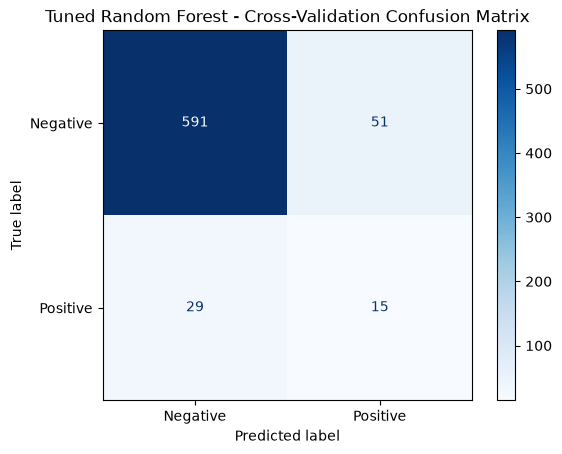

In [43]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

rf_cv_predictions = cross_val_predict(
    rf_best_model,
    X_train,
    Y_train,
    cv=cv
)

cm = confusion_matrix(Y_train, rf_cv_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues", values_format="d")

plt.title("Tuned Random Forest - Cross-Validation Confusion Matrix")
plt.show()


## Error Analysis
The confusion matrix above shows that the tuned Random Forest variation identified 591 negative cases and a total of 15 positive cases. It did however incorrectly predict 51 cases as positive and missed 29 actual positive cases. ALthough the performance of this model for identifying positive cases was better than both the baseline and KNN, it still missed the majority of them. This is a massive limitation considering that identifying positive biopsy results is the whole aim of the project. The model additionally produces a large number of false positives which shows the trade off in improving recall. Overall there is still room for improvement. 

## 5.8 Draft Conclusion
From the work done above, I have determined that my prefered model is the tuned Random Forest with 200 trees, max depth of 5 and balanced class weights due to the fact is has the highest recall of 33.89% and an F1 score of 27.13% compared to the other models. However, it still misses around two-thirds of positive cases which is a major limitation given the class imbalance in the dataset. The next steps that I will be exploring will be looking into improving minority-class detection and evaluate the above on the held-out test set.